# Dedaxon — Week 7: analysis of trajectory 35

This notebook analyses only `Dedaxon_odometry_data.txt`. Positions are in centimetres and time is in milliseconds. It plots the recorded trajectory against the planned 35 path and reports waypoint misses, run time and final odometry error.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

filename = 'Dedaxon_odometry_data.txt'
if not Path(filename).exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place Dedaxon_odometry_data.txt next to this notebook.')
    else:
        uploaded = files.upload()

wp = np.array([[0,0],[40,0],[40,-30],[0,-30],[40,-30],[40,-60],
               [0,-60],[105,0],[65,0],[65,-30],[105,-30],[105,-60],[65,-60]], dtype=float)

def load_log(name):
    data = np.loadtxt(name, delimiter=',', ndmin=2)
    if data.shape[1] != 3 or len(data) < 2 or not np.isfinite(data).all():
        raise ValueError(name + ': expected at least two finite x,y,time rows without a header')
    if np.any(np.diff(data[:,2]) < 0):
        raise ValueError(name + ': timestamps must not decrease')
    # Retain the last reading for duplicate timestamps before interpolation.
    _, reverse_indices = np.unique(data[::-1,2], return_index=True)
    data = data[np.sort(len(data)-1-reverse_indices)]
    if len(data) < 2:
        raise ValueError(name + ': need at least two distinct timestamps')
    data[:,2] -= data[0,2]
    return data

data = load_log(filename)
runs = {'Dedaxon odometry': data}
print(f'Samples: {len(data)}')
print(f'Run time: {data[-1,2]/1000:.3f} s')
print(f'Final odometry position: ({data[-1,0]:.3f}, {data[-1,1]:.3f}) cm')


Samples: 570
Run time: 73.271 s
Final odometry position: (66.086, -59.822) cm


## Planned path versus recorded trajectory

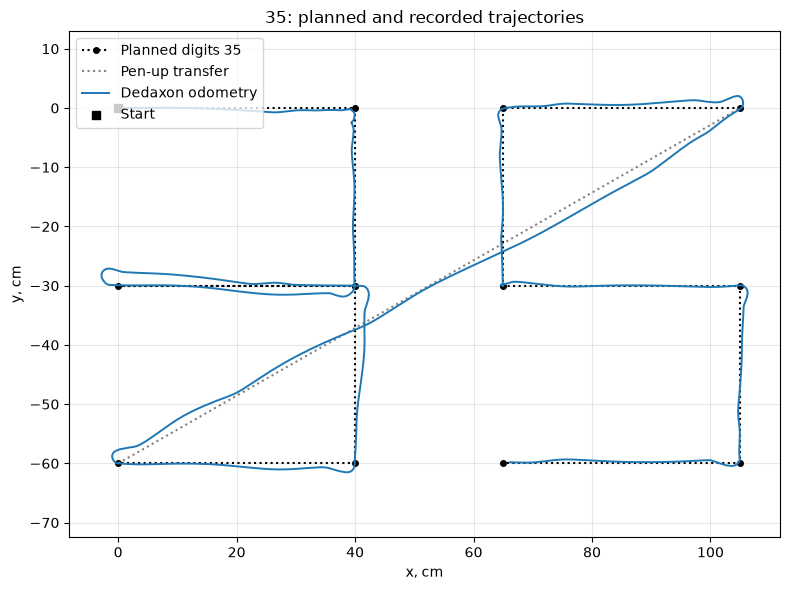

In [2]:
fig, ax = plt.subplots(figsize=(8,6))
ax.plot(wp[:7,0], wp[:7,1], 'k:o', label='Planned digits 35', markersize=4)
ax.plot(wp[7:,0], wp[7:,1], 'k:o', markersize=4)
ax.plot(wp[6:8,0], wp[6:8,1], ':', color='gray', label='Pen-up transfer')
for label, data in runs.items():
    ax.plot(data[:,0], data[:,1], label=label, linewidth=1.4)
ax.scatter([0], [0], color='black', marker='s', label='Start', zorder=5)
ax.set(xlabel='x, cm', ylabel='y, cm', title='35: planned and recorded trajectories')
ax.axis('equal'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.show()


## Waypoint misses and endpoint
Miss distance is the nearest logged point to each target. Repeated points can have identical misses; this metric alone does not establish that the controller visited every target in order.


In [3]:
def waypoint_miss(data):
    return np.array([np.min(np.hypot(data[:,0]-x, data[:,1]-y)) for x,y in wp])

for label, data in runs.items():
    print(label)
    print('Point     x(cm)    y(cm)    nearest miss(cm)')
    for i, ((x,y), miss) in enumerate(zip(wp, waypoint_miss(data))):
        print(f'{i:5d} {x:9.1f} {y:9.1f} {miss:19.3f}')
    endpoint_error = np.linalg.norm(data[-1,:2]-wp[-1])
    path_length = np.hypot(*np.diff(data[:,:2], axis=0).T).sum()
    print(f'Run time: {data[-1,2]/1000:.3f} s')
    print(f'Final odometry-to-target distance: {endpoint_error:.3f} cm')
    print(f'Logged odometry path length (including transfer): {path_length:.2f} cm')
    print()


Dedaxon odometry
Point     x(cm)    y(cm)    nearest miss(cm)
    0       0.0       0.0               0.000
    1      40.0       0.0               0.699
    2      40.0     -30.0               0.135
    3       0.0     -30.0               0.563
    4      40.0     -30.0               0.135
    5      40.0     -60.0               0.101
    6       0.0     -60.0               0.089
    7     105.0       0.0               0.138
    8      65.0       0.0               0.075
    9      65.0     -30.0               0.037
   10     105.0     -30.0               0.063
   11     105.0     -60.0               0.314
   12      65.0     -60.0               1.101
Run time: 73.271 s
Final odometry-to-target distance: 1.101 cm
Logged odometry path length (including transfer): 539.98 cm



## Discussion

The recorded trajectory follows the planned digits 35, including the transfer between them. The log contains 570 samples over 73.271 seconds. The final odometry position is (66.086, −59.822) cm, giving a distance of 1.101 cm from the final target (65, −60) cm. Small excursions appear around several corners; motor momentum, steering response and the 1.2 cm waypoint acceptance radius can contribute. These results describe tracking according to encoder odometry; physical position accuracy would require an independent measurement.